In [1]:
import matplotlib.pyplot as plt
import numpy as np
import importlib

# import custom functions
import  bilinear_interpolation
import cube_decube
import read_fits
import support

# reload custom function after every cell run
importlib.reload(bilinear_interpolation)
importlib.reload(cube_decube)
importlib.reload(read_fits)
importlib.reload(support)

<module 'support' from '/home/stefan/files/Projects/Licenta/src/src/support.py'>

In [2]:
detector_layout = '../assets/CRS-HERA-SW101-HyperScout-H-detector-per-pixel-central-wavelength-map.fits'
mars = '../assets/HS-L0-FE-025D-05-01_1C.fits'

In [3]:
mars_data, layout_data = read_fits.read(
    mars,
    detector_layout
)

In [4]:
hyp_cube = cube_decube.cube(
    mars_data,
    layout_data
)

/home/stefan/files/Projects/Licenta/src/.venv/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/stefan/files/Projects/Licenta/src/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


In [5]:
interpolated_cube = bilinear_interpolation.interpolate(
    hyp_cube,
    layout_data
)

In [6]:
reduced_cube = support.reduce_intwerp(
    interpolated_cube,
    hyp_cube
)

In [7]:
interpolated_reduced_image = cube_decube.decube(
    reduced_cube,
    layout_data
)

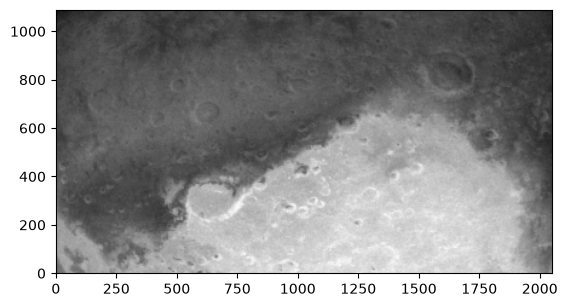

In [8]:
plt.imshow(interpolated_reduced_image, origin = 'lower', cmap = 'grey')

In [9]:
diff_image = interpolated_reduced_image[:1088, :2048] - mars_data[:1088, :2048]

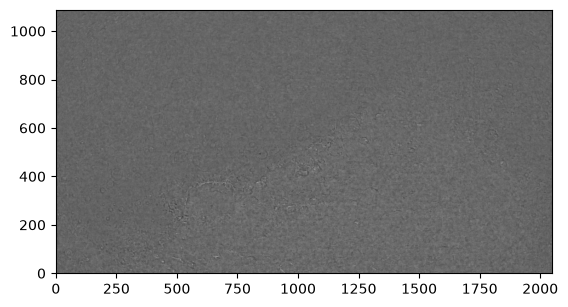

In [10]:
plt.imshow(diff_image, origin = 'lower', cmap = 'grey')

In [14]:
med_ae = np.median(np.abs(diff_image))

In [15]:
rmse = np.sqrt(np.mean((med_ae) ** 2))

In [19]:
print(f'Median Absolute Error = {med_ae} \nRMSE = {rmse * 100} %')

Median Absolute Error = 0.014512872243994529 
RMSE = 1.451287224399453 %
